# AM とリング変調

**変調**は、伝えたい信号(音声など)を、もっと高い周波数の**搬送波**に乗せることです。AM ラジオは、搬送波の振幅を信号に合わせて変えて送ります(**振幅変調**、AM)。搬送波を消して、信号と搬送波の積だけを取り出すものを**リング変調**(平衡変調、DSB)といい、無線(SSB)や電子楽器の金属的な音に使われます。どちらも、2 つの電圧を掛け算する**乗算器**で作ります。

この回では、AM の波形と変調度、スペクトルに現れる側帯波、変調度が 100 % を超えたとき(過変調)を見ます。

## 回路

![AM / リング変調器(ブロック図)](04_modulator/circuit.svg)

入力の信号に直流 A を足し、発振器の搬送波と掛け算します。A があれば AM、A = 0 ならリング変調です。乗算器には、MC1496 のようなトランジスタの差動回路(ギルバート・セル)がよく使われます。

## 原理

信号を $s(t)$、搬送波を $\sin 2\pi f_c t$(振幅 $A_c$)とします。

$$\text{AM:}\quad A_c\,(1 + m\,s(t))\sin 2\pi f_c t \qquad\qquad \text{リング:}\quad k\,s(t)\sin 2\pi f_c t$$

AM の**変調度** $m$ は、包絡線(振幅の外形)の最大と最小から $m = (\max - \min) / (\max + \min)$ で求められます。

| | 包絡線 | スペクトル(信号が周波数 $f_m$ の正弦波のとき) |
|---|---|---|
| AM | 信号の形 | 搬送波 $f_c$ と、両側の**側帯波** $f_c \pm f_m$(振幅は $m A_c / 2$) |
| リング | 信号の絶対値の形。信号が 0 を横切るところで搬送波が反転する | 側帯波 $f_c \pm f_m$ だけ(搬送波は消える) |

$\sin a \sin b = \frac{1}{2}\{\cos(a - b) - \cos(a + b)\}$ なので、掛け算すると周波数の**和と差**ができます。これが側帯波です。

$m > 1$(**過変調**)では、$1 + m\,s(t)$ が負になるところで搬送波が反転し、包絡線は信号の形ではなくなります。5-5 のエンベロープで包絡線を取り出すと、ひずんでしまいます。

![AM とリング変調(模式図)](04_modulator/response.svg)

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.am(fc, ac, depth, wave)` | `mimic.setAmModulator(fc, ac, depth, MIMIC_OSC_WAVE_SINE)` など | 搬送波の周波数 $f_c$(Hz)と振幅 $A_c$(V)、1 V あたりの変調度 `depth`(入力の振幅が $a$ V なら $m$ = depth × $a$) |
| `lab.mimic.ring(fc, gain, wave)` | `mimic.setRingModulator(fc, gain, MIMIC_OSC_WAVE_SINE)` など | 搬送波の周波数 $f_c$(Hz)、ゲイン $k$(入力 × 搬送波の山の値) |

- 入力の信号は、Vref(2.5 V)を 0 として扱います。
- 出力は 0.1〜4.9 V までなので、$A_c(1 + m)$ が 2.4 V を超えないようにします。
- 下の準備のセルの `amplitudes` はスペクトル(周波数ごとの振幅)、`peaks` は強い周波数、`depth` は包絡線から変調度を求めます。

## 準備:測定器につなぐ

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.4, mimic=20261125)

In [2]:
def show(t, ch1, ch2, label):
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.plot(t * 1e3, ch1, label="CH1: input (signal)")
    ax.plot(t * 1e3, ch2, lw=0.8, label=f"CH2: output ({label})")
    ax.set_xlabel("Time [ms]")
    ax.set_ylabel("Voltage [V]")
    ax.grid(True)
    ax.legend(loc="upper right")
    plt.show()


def amplitudes(t, v):
    # Amplitude (V) of each frequency (Hz), with a Hann window: (Hz, V)
    w = np.hanning(len(v))
    spec = np.abs(np.fft.rfft((v - v.mean()) * w)) * 2 / w.sum()
    return np.fft.rfftfreq(len(v), t[1] - t[0]), spec


def peaks(t, v, count=3, low=100):
    # The strongest frequencies above low Hz: [(Hz, V), ...]
    f, a = amplitudes(t, v)
    top = [i for i in np.argsort(a)[::-1] if f[i] > low and a[i] >= a[max(i - 1, 0)] and a[i] >= a[min(i + 1, len(a) - 1)]]
    return [(f[i], a[i]) for i in sorted(top[:count])]


def depth(t, v, carrier_period=1e-3):
    # Modulation depth m from the envelope: the largest |v - 2.5| in each carrier period
    n = round(carrier_period / (t[1] - t[0]))
    env = np.abs(v[: len(v) // n * n] - 2.5).reshape(-1, n).max(axis=1)
    return (env.max() - env.min()) / (env.max() + env.min())

## 実験 1:AM

信号は 50 Hz、振幅 0.5 V の正弦波、搬送波は 1 kHz、振幅 1 V、1 V あたりの変調度 1 にします。変調度は $m$ = 1 × 0.5 = 0.5 で、出力の振幅は 0.5〜1.5 V のあいだを、信号に合わせて変わるはずです。

modulation depth m = 0.50 (theory 0.50)


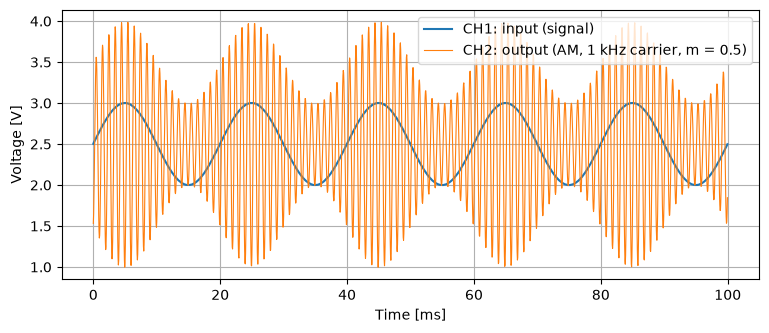

In [3]:
lab.fg.sine(50, 0.5)
lab.mimic.am(1000, 1.0, 1.0)
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s
print(f"modulation depth m = {depth(t, ch2):.2f} (theory 0.50)")
show(t, ch1, ch2, "AM, 1 kHz carrier, m = 0.5")

出力の山をつないだ線(包絡線)が、入力の信号と同じ形になっています。AM ラジオは、この包絡線を検波(5-5)して音を取り出します。

## 実験 2:スペクトル

AM とリング変調の出力のスペクトルをくらべます。AM では 1000 Hz(搬送波)と 950、1050 Hz(側帯波、振幅 0.25 V)、リング変調では 950 と 1050 Hz だけが出るはずです。

AM: 950 Hz 0.246 V, 1000 Hz 0.986 V, 1050 Hz 0.247 V
ring: 950 Hz 0.246 V, 1050 Hz 0.246 V


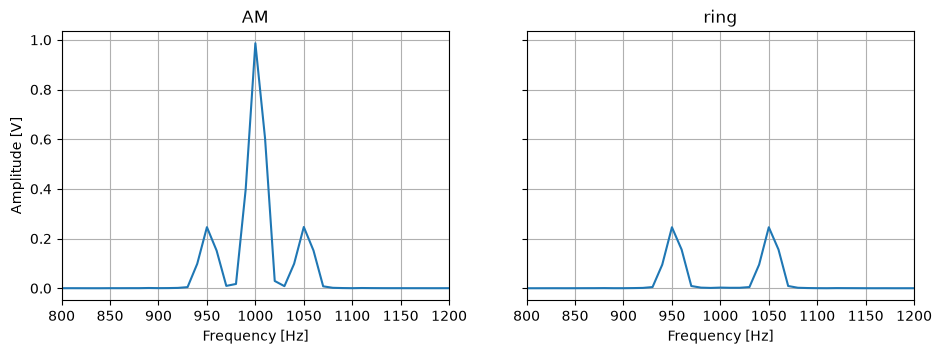

In [4]:
lab.fg.sine(50, 0.5)
lab.mimic.am(1000, 1.0, 1.0)
time.sleep(0.1)
t, ch1, ch2_am = lab.scope.capture(2000)
lab.mimic.ring(1000, 1.0)
time.sleep(0.1)
t, ch1, ch2_ring = lab.scope.capture(2000)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, v, name in zip(axes, (ch2_am, ch2_ring), ("AM", "ring")):
    print(name + ": " + ", ".join(f"{f:.0f} Hz {a:.3f} V" for f, a in peaks(t, v, 3 if name == "AM" else 2)))
    f, a = amplitudes(t, v)
    ax.plot(f, a)
    ax.set_xlim(800, 1200)
    ax.set_title(name)
    ax.set_xlabel("Frequency [Hz]")
    ax.grid(True)
axes[0].set_ylabel("Amplitude [V]")
plt.show()

リング変調では搬送波の 1000 Hz が消え、和と差の周波数だけが残ります。信号の情報は側帯波に入っているので、AM の搬送波は情報を運ばない「むだな」電力ともいえます。片側の側帯波だけを送る SSB は、この考えで電力と帯域を節約します。

## 実験 3:過変調

1 V あたりの変調度を 3 にして、$m$ = 1.5 にします。包絡線が 0 を下回るところで、搬送波が反転するはずです。

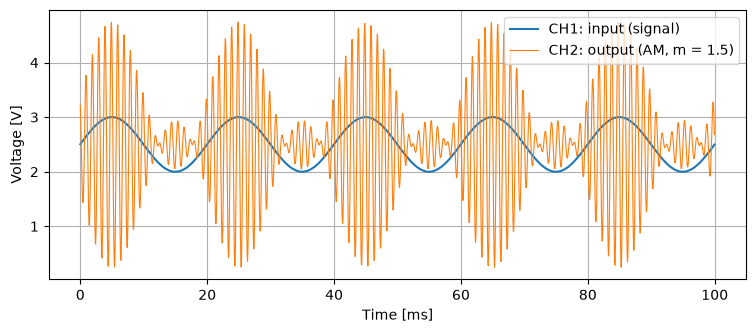

In [5]:
lab.fg.sine(50, 0.5)
lab.mimic.am(1000, 0.9, 3.0)
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
show(t, ch1, ch2, "AM, m = 1.5")

信号の谷のあたりで、振幅がいったん 0 まで下がってから、また大きくなっています。この部分では搬送波の向きが逆になっていて、包絡線は信号の正弦波の形になりません(搬送波の振幅は、出力の範囲に収まるように 0.9 V にしています)。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 変調度を変える
<details><summary>ヒント</summary>

`DEPTH` を 0.4 → 2.0 → 1.0 と変えてみましょう。信号の振幅は 0.5 V なので、$m$ = 0.2、1.0、0.5 です。

- 0.2:振幅の変化は小さく、ほとんど一定の搬送波に見えます。
- 2.0($m$ = 1):信号の谷で、振幅がちょうど 0 になります。

</details>

m = 0.20 (theory 0.20)


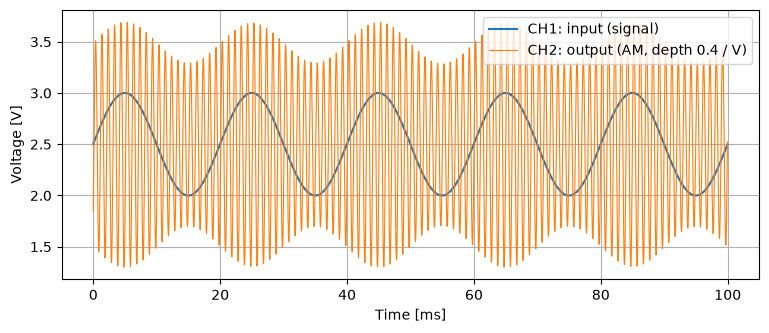

In [6]:
DEPTH = 0.4   # modulation depth per volt [1/V]

lab.fg.sine(50, 0.5)
lab.mimic.am(1000, 1.0, DEPTH)
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"m = {depth(t, ch2):.2f} (theory {DEPTH * 0.5:.2f})")
show(t, ch1, ch2, f"AM, depth {DEPTH} / V")

### 2. 信号の周波数を変える
<details><summary>ヒント</summary>

`F_SIGNAL` を 20 → 100 → 200 Hz と変えてみましょう。リング変調の側帯波は $1000 \pm f_m$ で、980 と 1020、900 と 1100、800 と 1200 Hz に動きます。

</details>

ring: 980 Hz 0.247 V, 1020 Hz 0.245 V


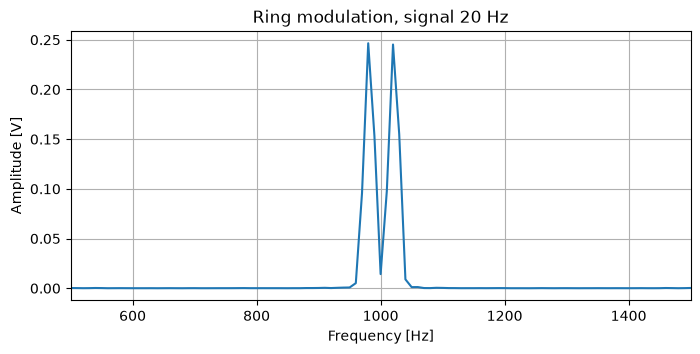

In [7]:
F_SIGNAL = 20   # [Hz]

lab.fg.sine(F_SIGNAL, 0.5)
lab.mimic.ring(1000, 1.0)
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
print("ring: " + ", ".join(f"{f:.0f} Hz {a:.3f} V" for f, a in peaks(t, ch2, 2)))
f, a = amplitudes(t, ch2)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(f, a)
ax.set_xlim(500, 1500)
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel("Amplitude [V]")
ax.set_title(f"Ring modulation, signal {F_SIGNAL} Hz")
ax.grid(True)
plt.show()

### 3. 方形波の搬送波(チョッパ)
<details><summary>ヒント</summary>

`WAVE` を `"square"` にしてみましょう。方形波の搬送波との掛け算は、入力の向きを 1 ms ごとに切り替える(**チョッパ**)のと同じです。方形波は 1、3、5 … 倍の周波数を含むので、側帯波は 1 kHz のまわりだけでなく、3 kHz、5 kHz … のまわりにも出ます。

</details>

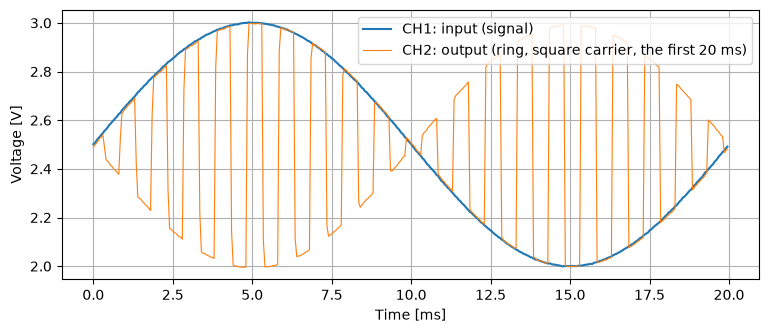

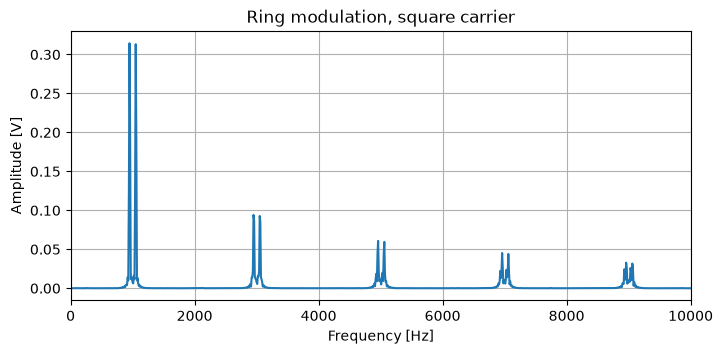

In [8]:
WAVE = "square"   # "sine" or "square"

lab.fg.sine(50, 0.5)
lab.mimic.ring(1000, 1.0, WAVE)
time.sleep(0.1)
t, ch1, ch2 = lab.scope.capture(2000)
show(t[:400], ch1[:400], ch2[:400], f"ring, {WAVE} carrier, the first 20 ms")
f, a = amplitudes(t, ch2)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(f, a)
ax.set_xlim(0, 10000)
ax.set_xlabel("Frequency [Hz]")
ax.set_ylabel("Amplitude [V]")
ax.set_title(f"Ring modulation, {WAVE} carrier")
ax.grid(True)
plt.show()

## まとめ

- AM は、搬送波の振幅を信号に合わせて変える。包絡線が信号の形になり、スペクトルには搬送波と側帯波 $f_c \pm f_m$ が出る。
- リング変調(平衡変調)は信号 × 搬送波で、和と差の周波数だけが出る(搬送波は消える)。
- 変調度が 1 を超える(過変調)と、搬送波が反転して包絡線が信号の形でなくなる。
- Mimic では `am(fc, ac, depth, wave)`、`ring(fc, gain, wave)`。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [9]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()